# LSTM Classification

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This file implements the LSTM model for document classification.

### Import the required libraries

In [95]:
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score

### Loading the data



In [96]:
# Read the processed dataset
data = pd.read_csv("../synthetic_dataset/document_classified_data.csv")

# Split the string based on space
data["processed_text"] = data["processed_text"].astype("str").apply(lambda x: x.split())

# Load Tokenizers
with open("output/doc_text_tokenizer.pickle", "rb") as file:
    tokenizer = pickle.load(file)

# Load GloVe word embeddings for the docs
with np.load("output/doc_glove_embeddings.npz", allow_pickle=True) as glove_embeddings_data:
    glove_embeddings = glove_embeddings_data["embedding_matrix"]

glove_embeddings.shape

(22262, 300)

In [97]:
# Convert the tokens to sequences
sequences = tokenizer.texts_to_sequences(data["processed_text"])

# Padding the sequences
text_max_len = 100

text_padded_sequences = tf.keras.preprocessing.sequence.pad_sequences(sequences, maxlen=text_max_len, padding="post")

### Model Creation

In [98]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(text_padded_sequences, data["sensitive"], test_size=0.2, random_state=42)

# Build the LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=glove_embeddings.shape[0], output_dim=glove_embeddings.shape[1], weights=[glove_embeddings], input_length=text_max_len, trainable=False),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_11 (Embedding)    (None, 100, 300)          6678600   
                                                                 
 lstm_17 (LSTM)              (None, 100, 128)          219648    
                                                                 
 dropout_24 (Dropout)        (None, 100, 128)          0         
                                                                 
 lstm_18 (LSTM)              (None, 64)                49408     
                                                                 
 dropout_25 (Dropout)        (None, 64)                0         
                                                                 
 dense_20 (Dense)            (None, 32)                2080      
                                                                 
 dropout_26 (Dropout)        (None, 32)              

### Training and Evaluation



In [99]:
# Adjusting optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=7, batch_size=32, validation_split=0.1)

Epoch 1/7
27/27 [==============================] - 6s 69ms/step - loss: 0.6744 - accuracy: 0.5799 - val_loss: 0.6888 - val_accuracy: 0.5521
Epoch 2/7
27/27 [==============================] - 1s 19ms/step - loss: 0.6235 - accuracy: 0.6562 - val_loss: 0.6186 - val_accuracy: 0.6979
Epoch 3/7
27/27 [==============================] - 1s 19ms/step - loss: 0.5778 - accuracy: 0.6910 - val_loss: 0.5718 - val_accuracy: 0.7083
Epoch 4/7
27/27 [==============================] - 0s 13ms/step - loss: 0.5183 - accuracy: 0.7558 - val_loss: 0.5230 - val_accuracy: 0.7604
Epoch 5/7
27/27 [==============================] - 0s 13ms/step - loss: 0.4581 - accuracy: 0.7731 - val_loss: 0.6073 - val_accuracy: 0.7604
Epoch 6/7
27/27 [==============================] - 0s 12ms/step - loss: 0.4361 - accuracy: 0.7940 - val_loss: 0.6028 - val_accuracy: 0.6771
Epoch 7/7
27/27 [==============================] - 0s 13ms/step - loss: 0.3779 - accuracy: 0.8333 - val_loss: 0.6850 - val_accuracy: 0.6875


In [100]:
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

df_scores = pd.DataFrame(columns=["Metric", "Value"])
df_scores = df_scores._append({"Metric": "Accuracy", "Value":accuracy}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Precision", "Value":precision}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Recall", "Value":recall}, ignore_index=True)
df_scores = df_scores._append({"Metric": "F1 score:", "Value":f1}, ignore_index=True)

df_scores.head()

8/8 [==============================] - 1s 6ms/step


,Metric,Value
0,Accuracy,0.625000
1,Precision,0.631579
2,Recall,0.800000
3,F1 score:,0.705882


### Plotting the accuracy

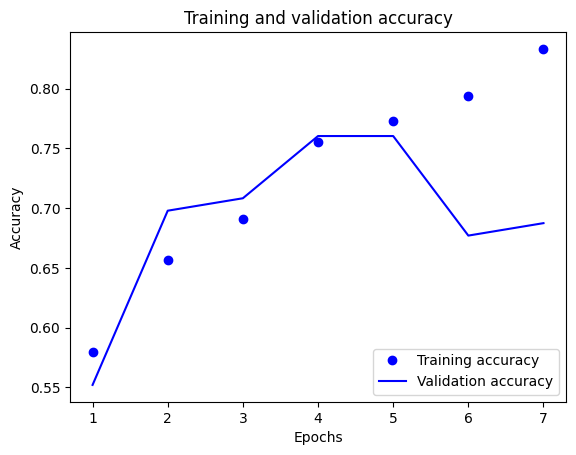

In [101]:
# Plotting the accuracy
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.show()